# Machine Learning Analysis of stock Market Data clustering and time series forecasting approach

# Lets import libraries

In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.metrics import mean_absolute_error, mean_squared_error

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Set default figure size
plt.rcParams["figure.figsize"] = (12, 6)

In [3]:
import yfinance as yf

# Choose 10 stocks
stocks = ["NFLX", "ORCL", "IBM", "QCOM", "ADBE", "INTU", "CSCO", "TXN", "AMD", "CRM"]

for stock in stocks:
    df = yf.download(stock, start="2016-01-01", end="2025-12-31")
    df.reset_index(inplace=True)   # make Date a normal column 
    df.to_csv(f"{stock}.csv", index=False)
    print(f"{stock} saved")

print("Download complete!")

[*********************100%***********************]  1 of 1 completed


NFLX saved


[*********************100%***********************]  1 of 1 completed


ORCL saved


[*********************100%***********************]  1 of 1 completed


...

TXN saved


[*********************100%***********************]  1 of 1 completed


AMD saved


[*********************100%***********************]  1 of 1 completed

CRM saved
Download complete!


 # Load all CSV files

In [4]:
# list of selscted stock tickers
stock = ["NFLX", "ORCL", "IBM", "QCOM", "ADBE", "INTU", "CSCO", "TXN", "AMD", "CRM"]

# Creat an empty list to store all stock data
all_data = []

for stock in stock:
     # Read each CSV file / CSV
    df = pd.read_csv(f"{stock}.csv")
    # Remove the first two incorrect rows 
    df = df.iloc[2:].copy()

    df.rename(columns={"Price": "Date"}, inplace=True)

    #Add stock name as a new column
    df["Stock"] = stock

    #Store cleaned file in the kist
    all_data.append(df)

#combine all stock data into one dataframe
combined_df = pd.concat(all_data, ignore_index=True)

#Preview the raw combined data
print(combined_df.head())
print(combined_df.shape)
print(combined_df.columns)


         Date               Close                High                 Low  \
0  2016-01-05  10.765999794006348  11.057999610900879  10.585000038146973   
1  2016-01-06  11.767999649047852  11.791000366210938  10.496000289916992   
2  2016-01-07  11.456000328063965  12.218000411987305  11.229000091552734   
3  2016-01-08  11.138999938964844  11.772000312805176  11.109999656677246   
4  2016-01-11  11.496999740600586  11.678999900817871  11.119999885559082   

                 Open     Volume Stock  
0  11.045000076293945  176646000  NFLX  
1  10.529000282287598  330457000  NFLX  
2   11.63599967956543  336367000  NFLX  
3  11.633000373840332  180671000  NFLX  
4  11.213000297546387  219204000  NFLX  
(25120, 7)
Index(['Date', 'Close', 'High', 'Low', 'Open', 'Volume', 'Stock'], dtype='str')


In [5]:
# Remove extra space from column names 
combined_df.columns = combined_df.columns.str.strip()

# Convert Date column to datetime format
combined_df["Date"] = pd.to_datetime(combined_df["Date"], errors="coerce")

# Convert numeric columns to numeric type
numeric_cols = ["Open", "High", "Low", "Close", "Volume"]
for col in numeric_cols:
        combined_df[col] = pd.to_numeric(combined_df[col], errors="coerce")
    
# Remove rows with missing Date or Close values/ 
combined_df = combined_df.dropna(subset=["Date", "Close"])

# Sort data by Stock and Date /
combined_df = combined_df.sort_values(by=["Stock", "Date"]).reset_index(drop=True)

#check missing values and preview cleaned data 
print (combined_df.isnull().sum())
print (combined_df.head())
print (combined_df.info())

Date      0
Close     0
High      0
Low       0
Open      0
Volume    0
Stock     0
dtype: int64
        Date      Close       High        Low       Open   Volume Stock
0 2016-01-05  92.339996  92.849998  91.410004  92.010002  1821300  ADBE
1 2016-01-06  91.019997  91.500000  90.239998  91.099998  1674000  ADBE
2 2016-01-07  89.110001  91.400002  88.709999  89.400002  2717800  ADBE
3 2016-01-08  87.849998  89.989998  87.629997  89.680000  2263400  ADBE
4 2016-01-11  89.379997  89.800003  87.839996  88.070000  2362200  ADBE
<class 'pandas.DataFrame'>
RangeIndex: 25120 entries, 0 to 25119
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    25120 non-null  datetime64[us]
 1   Close   25120 non-null  float64       
 2   High    25120 non-null  float64       
 3   Low     25120 non-null  float64       
 4   Open    25120 non-null  float64       
 5   Volume  25120 non-null  int64         
 6   Stock   25120 non

 # Create return column

In [6]:
# Calculate daily percentgw return for each stock
combined_df["Return"] = combined_df.groupby("Stock")["Close"].pct_change()
#preview Date, stock, close and return columns 
print (combined_df[["Date", "Stock", "Close", "Return"]].head(10))

        Date Stock      Close    Return
0 2016-01-05  ADBE  92.339996       NaN
1 2016-01-06  ADBE  91.019997 -0.014295
2 2016-01-07  ADBE  89.110001 -0.020984
3 2016-01-08  ADBE  87.849998 -0.014140
4 2016-01-11  ADBE  89.379997  0.017416
5 2016-01-12  ADBE  89.820000  0.004923
6 2016-01-13  ADBE  88.300003 -0.016923
7 2016-01-14  ADBE  89.800003  0.016988
8 2016-01-15  ADBE  89.169998 -0.007016
9 2016-01-19  ADBE  89.180000  0.000112


# Initial eploratory data analysis

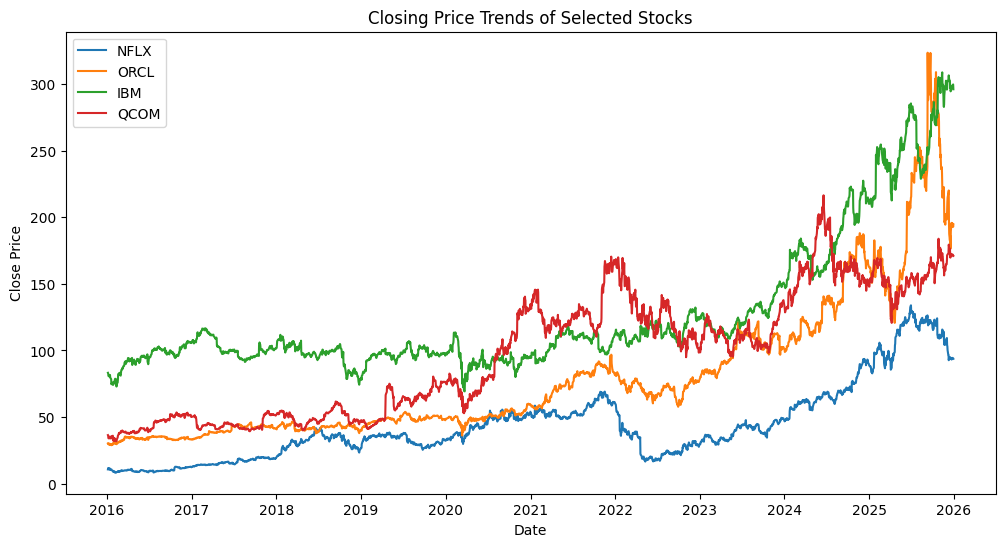

In [7]:
# Plot closing price trends for selected stocks
plt.figure(figsize=(12, 6))

for stock in ["NFLX", "ORCL", "IBM", "QCOM"]:
    temp= combined_df[combined_df["Stock"] ==stock]
    plt.plot(temp["Date"],temp["Close"], label=stock)

plt.title("Closing Price Trends of Selected Stocks")
plt.xlabel("Date")
plt.ylabel("Close Price")
plt.legend()
plt.show()

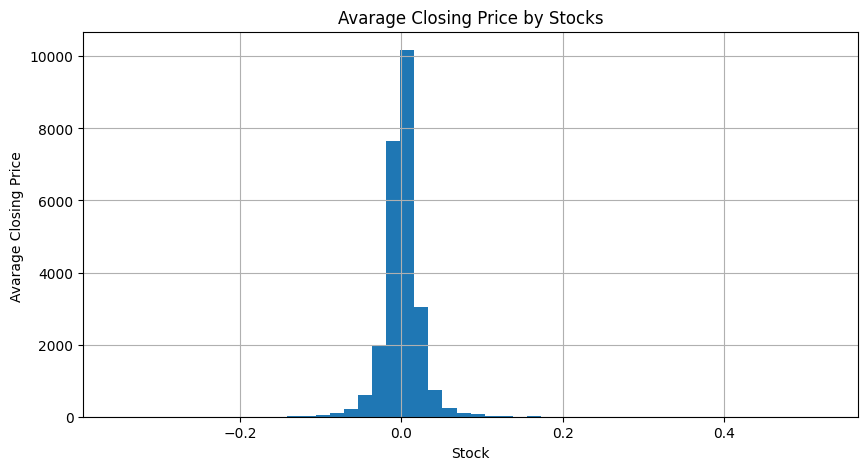

In [8]:
# Plot histogram of daily returns
plt.figure(figsize=(10, 5))
combined_df["Return"].dropna().hist(bins=50)
plt.title("Avarage Closing Price by Stocks")
plt.xlabel("Stock")
plt.ylabel("Avarage Closing Price ")
plt.show()

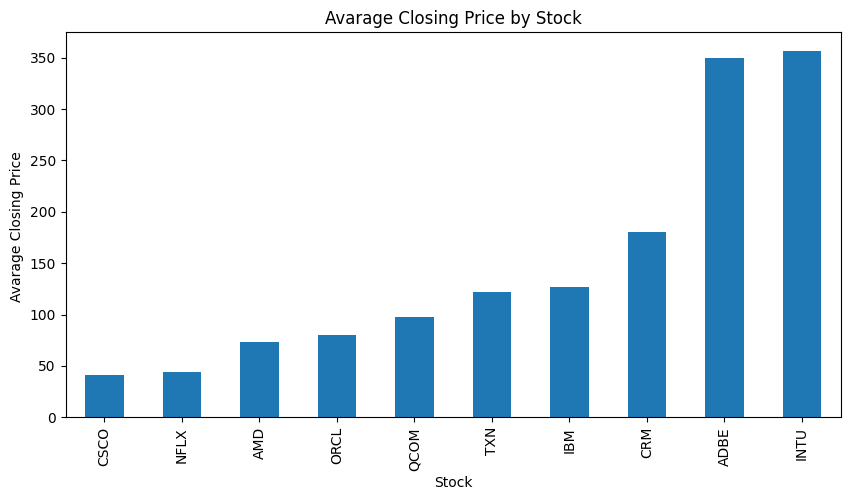

In [9]:
# Calculate average closing price by stock/
avg_close = combined_df.groupby("Stock")["Close"].mean().sort_values()

#Plot average close price
plt.figure(figsize=(10, 5))
avg_close.plot(kind="bar")

plt.title("Avarage Closing Price by Stock")
plt.xlabel("Stock")
plt.ylabel("Avarage Closing Price ")
plt.show()

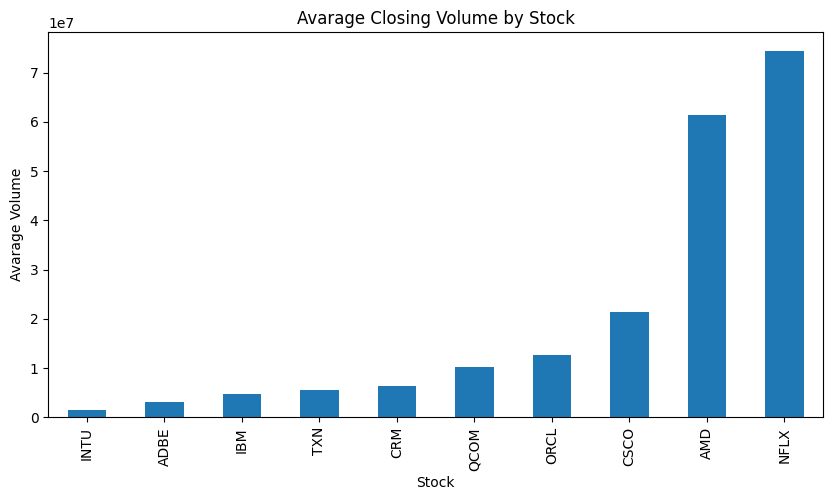

In [10]:
# Calculate average trading volume by stock/
avg_volume = combined_df.groupby("Stock")["Volume"].mean().sort_values()

#Plot average volume
plt.figure(figsize=(10, 5))
avg_volume.plot(kind="bar")

plt.title("Avarage Closing Volume by Stock")
plt.xlabel("Stock")
plt.ylabel("Avarage Volume")
plt.show()

In [11]:
# Aggregate importan features for each stock
features = combined_df.groupby("Stock").agg(
    Avg_Return=("Return", "mean"),
    Volatility=("Return", "std"),
    Avg_Volume=("Volume", "mean"),
    Avg_Price=("Close", "mean"),
    Max_Price=("Close", "max"),
    Min_Price=("Close", "min")
)
# Create price range feature / 
features["Price_Range"] = features["Max_Price"] - features["Min_Price"]

#drop missing values if any 
features = features.dropna()

#Preview feature dataset
print(features)

       Avg_Return  Volatility    Avg_Volume   Avg_Price   Max_Price  \
Stock                                                                 
ADBE     0.000762    0.021275  3.060247e+06  349.744482  688.369995   
AMD      0.002414    0.037262  6.141630e+07   73.489072  264.329987   
CRM      0.000741    0.022029  6.361425e+06  180.134327  362.581329   
CSCO     0.000675    0.015798  2.146152e+07   40.651720   78.791313   
IBM      0.000627    0.015599  4.813646e+06  126.763184  308.691681   
INTU     0.001005    0.019990  1.512440e+06  357.044857  794.713623   
NFLX     0.001219    0.026435  7.448658e+07   43.607031  133.912994   
ORCL     0.000950    0.020785  1.264125e+07   80.049466  323.433716   
QCOM     0.000893    0.023629  1.019375e+07   97.459754  216.441910   
TXN      0.000757    0.018761  5.429512e+06  122.302940  214.117279   

       Min_Price  Price_Range  
Stock                          
ADBE   73.849998   614.519997  
AMD     1.800000   262.529987  
CRM    53.037495   

# Scale features

In [12]:
# Select only imput features for clustering
feature_cols = ["Avg_Return", "Volatility", "Avg_Volume", "Avg_Price", "Max_Price"]

# Standardize the features
scaler = StandardScaler()
Scaled_features = scaler.fit_transform(features[feature_cols])

# Convert scaled array to dataframe for inspection
scaled_df = pd.DataFrame(Scaled_features, index=features.index, columns=feature_cols)
print(scaled_df)

       Avg_Return  Volatility  Avg_Volume  Avg_Price  Max_Price
Stock                                                          
ADBE    -0.486406   -0.148749   -0.691783   1.836830   1.601081
AMD      2.825983    2.549741    1.672141  -0.667536  -0.339631
CRM     -0.528304   -0.021458   -0.558057   0.299246   0.110038
CSCO    -0.659327   -1.073246    0.053627  -0.965220  -1.188789
IBM     -0.755581   -1.106855   -0.620755  -0.184585  -0.136600
INTU     0.000532   -0.365659   -0.754482   1.903011   2.087785
NFLX     0.430298    0.722235    2.201599  -0.938429  -0.936513
ORCL    -0.107906   -0.231526   -0.303670  -0.608064  -0.069130
QCOM    -0.223595    0.248655   -0.402814  -0.450232  -0.558801
TXN     -0.495695   -0.573138   -0.595807  -0.225019  -0.569440


 # Choose number of clusters using elbow method

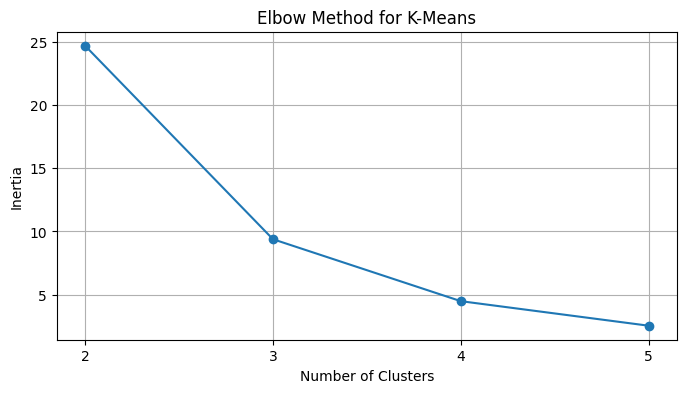

In [13]:
# Calculate interia values for different k values
inertia = []
k_values = range(2, 6)

for k in k_values:
    km = KMeans (n_clusters=k, random_state=42, n_init=10)
    km.fit(Scaled_features)
    inertia.append(km.inertia_)

# Plot elbow method 
plt.figure(figsize=(8, 4))
plt.plot(k_values, inertia, marker="o")
plt.title("Elbow Method for K-Means")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.xticks(k_values)
plt.grid(True)
plt.show()

 # K-Means clustering

In [14]:
# K-Means clustering 
kmeans = KMeans (n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(Scaled_features)

# Store K-means cluter labels
features["KMeans_Cluster"] = kmeans_labels

# View clutering results
print(features)

       Avg_Return  Volatility    Avg_Volume   Avg_Price   Max_Price  \
Stock                                                                 
ADBE     0.000762    0.021275  3.060247e+06  349.744482  688.369995   
AMD      0.002414    0.037262  6.141630e+07   73.489072  264.329987   
CRM      0.000741    0.022029  6.361425e+06  180.134327  362.581329   
CSCO     0.000675    0.015798  2.146152e+07   40.651720   78.791313   
IBM      0.000627    0.015599  4.813646e+06  126.763184  308.691681   
INTU     0.001005    0.019990  1.512440e+06  357.044857  794.713623   
NFLX     0.001219    0.026435  7.448658e+07   43.607031  133.912994   
ORCL     0.000950    0.020785  1.264125e+07   80.049466  323.433716   
QCOM     0.000893    0.023629  1.019375e+07   97.459754  216.441910   
TXN      0.000757    0.018761  5.429512e+06  122.302940  214.117279   

       Min_Price  Price_Range  KMeans_Cluster  
Stock                                          
ADBE   73.849998   614.519997               2  
AMD

# Agglomerative clustering

In [15]:
# Aplly Agglomerative clustering 
agg = AgglomerativeClustering (n_clusters=3)
agg_labels = agg.fit_predict(Scaled_features)

#Store Agglomerative cluster labels
features["Agglomerative_Cluster"] = agg_labels

#view clustering results
print(features)

       Avg_Return  Volatility    Avg_Volume   Avg_Price   Max_Price  \
Stock                                                                 
ADBE     0.000762    0.021275  3.060247e+06  349.744482  688.369995   
AMD      0.002414    0.037262  6.141630e+07   73.489072  264.329987   
CRM      0.000741    0.022029  6.361425e+06  180.134327  362.581329   
CSCO     0.000675    0.015798  2.146152e+07   40.651720   78.791313   
IBM      0.000627    0.015599  4.813646e+06  126.763184  308.691681   
INTU     0.001005    0.019990  1.512440e+06  357.044857  794.713623   
NFLX     0.001219    0.026435  7.448658e+07   43.607031  133.912994   
ORCL     0.000950    0.020785  1.264125e+07   80.049466  323.433716   
QCOM     0.000893    0.023629  1.019375e+07   97.459754  216.441910   
TXN      0.000757    0.018761  5.429512e+06  122.302940  214.117279   

       Min_Price  Price_Range  KMeans_Cluster  Agglomerative_Cluster  
Stock                                                                 
ADBE 

 # Evaluate clustering results

In [16]:
# Calculate Silhosihouette_score for both models
# A higher Silhouette Score generally indicates better-separated clusters
sil_kmeans = silhouette_score(Scaled_features, kmeans_labels)
sil_agg = silhouette_score(Scaled_features, agg_labels)

# Calculate Davis-Bouldin Index for both models
# A lower Davies-Bouldin Index generally indicates better clustering
db_kmeans = davies_bouldin_score(Scaled_features, kmeans_labels)
db_agg = davies_bouldin_score(Scaled_features, agg_labels)

# Check whether the two algorithms assigned the same label to every company.
print ("Cluster labels identical:", (kmeans_labels==agg_labels).all())

# Print evaluation metrics 
print (f"K-Means Silhoutete Score: {sil_kmeans:.4f}")
print (f"Agglomerative Silhouette Score:, {sil_agg:.4f}")
print (f"K-Means Davies-Bouldin Index:, {db_kmeans:.4f}")
print (f"Agglomerative Davies-Bouldin Index:, {db_agg:.4f}")


Cluster labels identical: True
K-Means Silhoutete Score: 0.5600
Agglomerative Silhouette Score:, 0.5600
K-Means Davies-Bouldin Index:, 0.5341
Agglomerative Davies-Bouldin Index:, 0.5341


# Visualize clutering

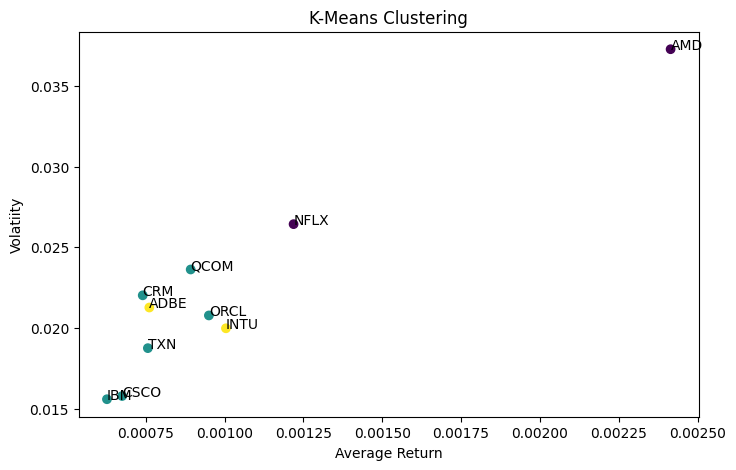

In [17]:
# Visualize K-Means clustering uisng average return and volatility 
plt.figure(figsize=(8, 5))

plt.scatter(
    features["Avg_Return"], 
    features["Volatility"], 
    c=features["KMeans_Cluster"]
)

for i in features.index:
    plt.text(
        features.loc[i, "Avg_Return"], 
        features.loc[i, "Volatility"], 
        str(i)
    )
    
plt.title("K-Means Clustering")
plt.xlabel("Average Return")
plt.ylabel("Volatiity")
plt.show()

# Time series analysis for AAPL

In [18]:
# Filter AAPL data for time series analysis 
aapl_df = combined_df[combined_df["Stock"] == "AAPL"].copy()

# Keep only Date and Close columns
aapl_df = aapl_df[["Date", "Close"]].dropna()

#Sort by date
aapl_df = aapl_df.sort_values("Date")

# Set By date index
aapl_df .set_index("Date", inplace=True)

# Preview AAPL dataframe
print(aapl_df.head())

Empty DataFrame
Columns: [Close]
Index: []


In [19]:
# Check the available stock symbols
print(combined_df["Stock"].unique())

# Check the shape of the dataset
print(combined_df.shape)

# Preview the original data
print(combined_df.head())

<StringArray>
['ADBE', 'AMD', 'CRM', 'CSCO', 'IBM', 'INTU', 'NFLX', 'ORCL', 'QCOM', 'TXN']
Length: 10, dtype: str
(25120, 8)
        Date      Close       High        Low       Open   Volume Stock  \
0 2016-01-05  92.339996  92.849998  91.410004  92.010002  1821300  ADBE   
1 2016-01-06  91.019997  91.500000  90.239998  91.099998  1674000  ADBE   
2 2016-01-07  89.110001  91.400002  88.709999  89.400002  2717800  ADBE   
3 2016-01-08  87.849998  89.989998  87.629997  89.680000  2263400  ADBE   
4 2016-01-11  89.379997  89.800003  87.839996  88.070000  2362200  ADBE   

     Return  
0       NaN  
1 -0.014295  
2 -0.020984  
3 -0.014140  
4  0.017416  


In [20]:
stocks = [
    'AAPL', 'NFLX', 'ORCL', 'IBM', 'QCOM',
    'ADBE', 'INTU', 'CSCO', 'TXN', 'AMD', 'CRM'
]

print(stocks)
print(len(stocks))

['AAPL', 'NFLX', 'ORCL', 'IBM', 'QCOM', 'ADBE', 'INTU', 'CSCO', 'TXN', 'AMD', 'CRM']
11


In [21]:
import yfinance as yf
import pandas as pd

all_data = []

for stock in stocks:
    df = yf.download(
        stock,
        start="2016-01-01",
        end="2026-01-01",
        auto_adjust=False,
        progress=False
    )

    if df.empty:
        print(f"No data downloaded for {stock}")
        continue

    # Handle column names returned by yfinance
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)

    df = df.reset_index()
    df["Stock"] = stock
    all_data.append(df)

combined_df = pd.concat(all_data, ignore_index=True)

print("Stocks loaded:", combined_df["Stock"].unique())
print("Dataset shape:", combined_df.shape)

Stocks loaded: <StringArray>
['AAPL', 'NFLX', 'ORCL',  'IBM', 'QCOM', 'ADBE', 'INTU', 'CSCO',  'TXN',
  'AMD',  'CRM']
Length: 11, dtype: str
Dataset shape: (27654, 8)


In [22]:
print(combined_df[combined_df["Stock"] == "AAPL"].head())
print("AAPL rows:", (combined_df["Stock"] == "AAPL").sum())

Price       Date  Adj Close      Close       High        Low       Open  \
0     2016-01-04  23.688681  26.337500  26.342501  25.500000  25.652500   
1     2016-01-05  23.095051  25.677500  26.462500  25.602501  26.437500   
2     2016-01-06  22.643085  25.174999  25.592501  24.967501  25.139999   
3     2016-01-07  21.687447  24.112499  25.032499  24.107500  24.670000   
4     2016-01-08  21.802128  24.240000  24.777500  24.190001  24.637501   

Price     Volume Stock  
0      270597600  AAPL  
1      223164000  AAPL  
2      273829600  AAPL  
3      324377600  AAPL  
4      283192000  AAPL  
AAPL rows: 2514


In [23]:
aapl_df = combined_df[
    combined_df["Stock"] == "AAPL"
][["Date", "Close"]].dropna().copy()

aapl_df["Date"] = pd.to_datetime(aapl_df["Date"])
aapl_df = aapl_df.sort_values("Date")
aapl_df.set_index("Date", inplace=True)

print(aapl_df.head())
print("Number of rows:", len(aapl_df))

Price           Close
Date                 
2016-01-04  26.337500
2016-01-05  25.677500
2016-01-06  25.174999
2016-01-07  24.112499
2016-01-08  24.240000
Number of rows: 2514


# Plot AAPL close price 

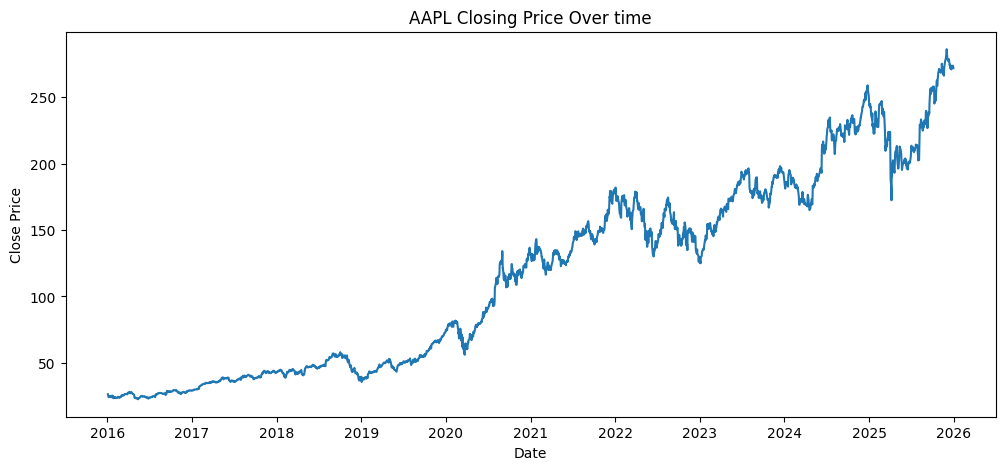

In [24]:
# Plot AAPL closing price over time
plt.figure(figsize=(12, 5))
plt.plot(aapl_df.index, aapl_df["Close"])
plt.title("AAPL Closing Price Over time")
plt.xlabel("Date")
plt.ylabel("Close Price")
plt.show()

# Rolling mean and rolling standart deviation 

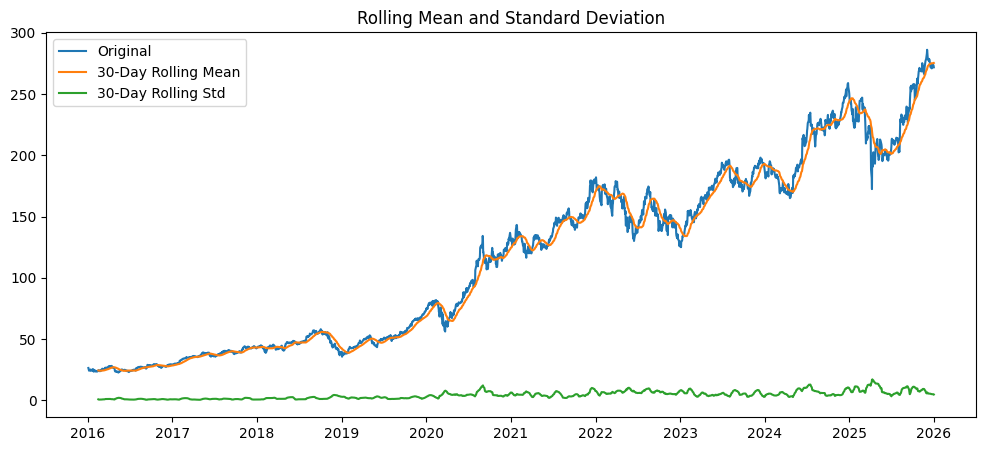

In [25]:
# Calculate rolling mean and rolling standard deviation
rolling_mean = aapl_df["Close"].rolling(window=30).mean()
rolling_std = aapl_df["Close"].rolling(window=30).std()

# Plot rolling statistics
plt.figure(figsize=(12, 5))
plt.plot(aapl_df["Close"], label="Original")
plt.plot(rolling_mean, label="30-Day Rolling Mean")
plt.plot(rolling_std, label="30-Day Rolling Std")
plt.title("Rolling Mean and Standard Deviation")
plt.legend()
plt.show()

# ADF test for stationarity

In [26]:
# Apply Augmented Dickey-fuller test
adf_result = adfuller(aapl_df["Close"].dropna())

print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])
print("Critical Values:")
for key, value in adf_result[4].items():
    print(f"{key}: {value}")

ADF Statistic: 0.3194424658561618
p-value: 0.9782191205620703
Critical Values:
1%: -3.4329652692893364
5%: -2.8626954126892405
10%: -2.567385070816339


# Differencing

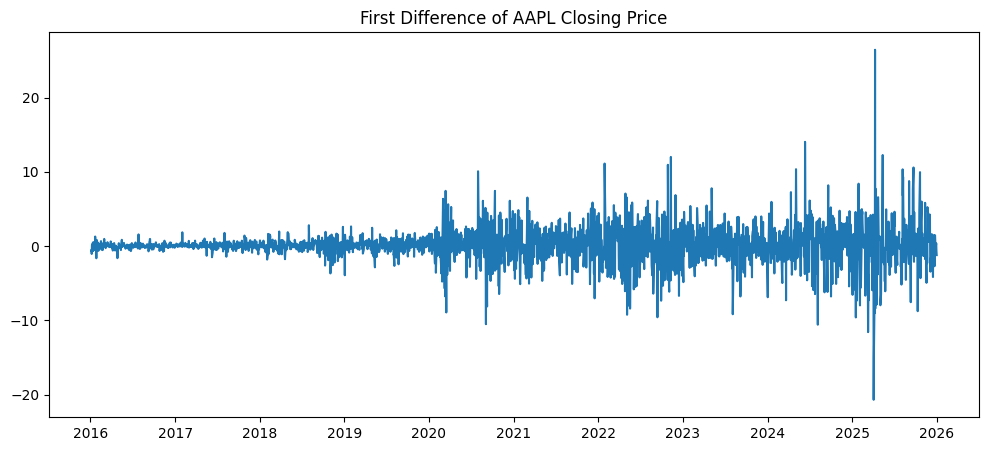

In [27]:
# Compute first difference of series 
aapl_df["Close_diff"] = aapl_df["Close"].diff()

# Plot differenced series / 
plt.figure(figsize=(12, 5))
plt.plot(aapl_df["Close_diff"])
plt.title("First Difference of AAPL Closing Price")
plt.show()


# ADF and PACF plots 

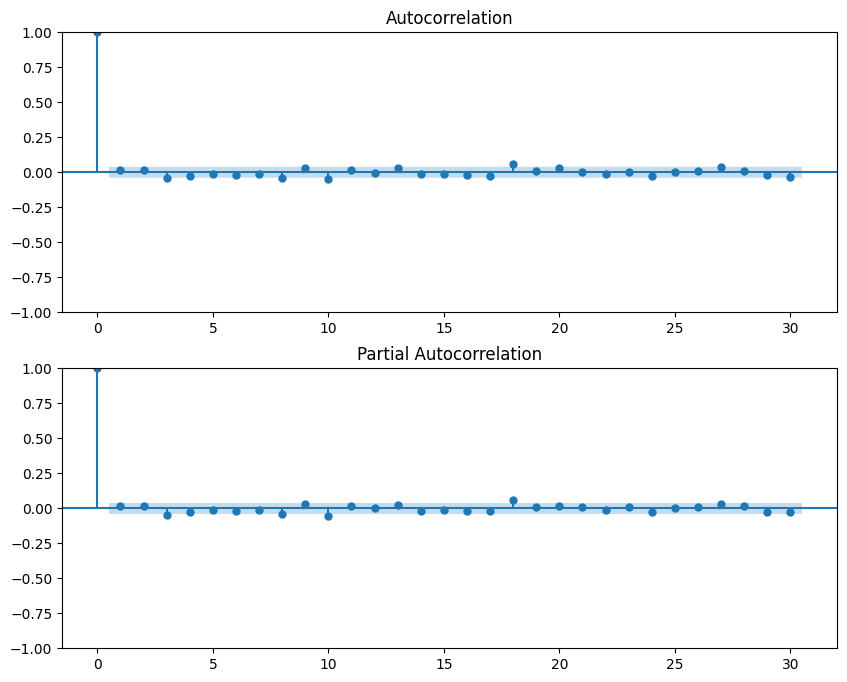

In [29]:
# Plot ACF and PACF to help choose p and q
fig, ax = plt.subplots(2, 1, figsize=(10, 8))
plot_acf(aapl_df["Close_diff"].dropna(), ax=ax[0], lags=30)
plot_pacf(aapl_df["Close_diff"].dropna(), ax=ax[1], lags=30)
plt.show()

notes

# Train=test split

In [30]:
# Split the data into training and testing sets
train_size = int (len(aapl_df) *0.8)
train = aapl_df["Close"][:train_size]
test = aapl_df["Close"][train_size:]

print("Train size:", len(train))
print("Test size:", len(test))

Train size: 2011
Test size: 503


# ARIMA model

In [31]:
# Fit ARIMA model
arima_model = ARIMA(train, order= (1, 1, 1))
arima_result = arima_model.fit()

# Forecast test period 
arima_forecast = arima_result.forecast(steps=len(test))

/Users/iku/anaconda3/envs/anaconda3/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/Users/iku/anaconda3/envs/anaconda3/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/Users/iku/anaconda3/envs/anaconda3/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/Users/iku/anaconda3/envs/anaconda3/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will 

In [32]:
# Fit SARIMA model 
sarima_model = SARIMAX(train, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12))
sarima_result = sarima_model.fit(disp=False)

# Forecast test period 
sarima_forecast = sarima_result.forecast(steps=len(test))

/Users/iku/anaconda3/envs/anaconda3/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/Users/iku/anaconda3/envs/anaconda3/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/Users/iku/anaconda3/envs/anaconda3/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(


# Evaluate Forecasing performance 

In [33]:
# Define RMSE function 
def rmse(actual, predicted):
    return np.sqrt(mean_squared_error(actual, predicted))

# Define MAPE function
def mape(actual, predicted):
    actual, predicted = np.array(actual), np.array(predicted)
    return np.mean(np.abs((actual - predicted) / actual)) * 100

# Print ARIMA evaluation metrics 
print("ARIMA MAE:", mean_absolute_error(test, arima_forecast))
print("ARIMA RMSE:", rmse(test, arima_forecast))
print("ARIMA MAPE:", mape(test, arima_forecast))

# Print SARIMA evaluation metrics 
print("SARIMA MAE:", mean_absolute_error(test, sarima_forecast))
print("SARIMA RMSE:", rmse(test, sarima_forecast))
print("SARIMA MAPE:", mape(test, sarima_forecast))

ARIMA MAE: 31.820394368347156
ARIMA RMSE: 38.83374240047435
ARIMA MAPE: 13.614352788983059
SARIMA MAE: 19.554080832050758
SARIMA RMSE: 22.42648359152385
SARIMA MAPE: 8.864050164473687


# Plot forecast result

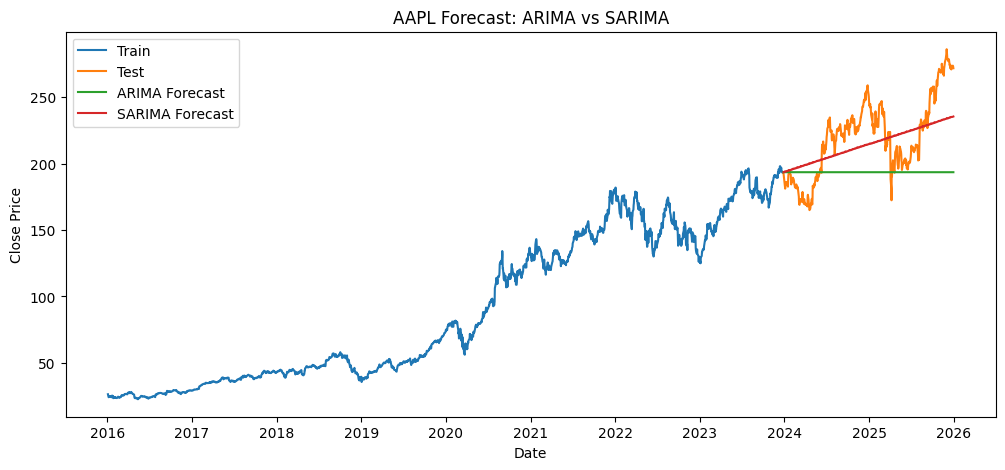

In [34]:
# Plot train, test and forecast values 
plt.figure(figsize=(12, 5))
plt.plot(train.index, train, label="Train")
plt.plot(test.index, test, label="Test")
plt.plot(test.index, arima_forecast, label="ARIMA Forecast")
plt.plot(test.index, sarima_forecast, label="SARIMA Forecast")
plt.title("AAPL Forecast: ARIMA vs SARIMA")
plt.xlabel("Date")
plt.ylabel("Close Price")
plt.legend()
plt.show()

# Optional future forecast

In [35]:
print(ARIMA)

<class 'statsmodels.tsa.arima.model.ARIMA'>


In [36]:
from statsmodels.tsa.arima.model import ARIMA

In [37]:
# Fit ARIMA on the full AAPL series
final_model = ARIMA(aapl_df["Close"], order=(1, 1, 1))
final_result = final_model.fit()

# Forecast the next 30 periods
future_forecast = final_result.forecast(steps=30)

print(future_forecast)

2514    271.860732
2515    271.860231
2516    271.860567
2517    271.860341
2518    271.860493
2519    271.860391
2520    271.860460
2521    271.860414
2522    271.860445
2523    271.860424
2524    271.860438
2525    271.860428
2526    271.860435
2527    271.860430
2528    271.860433
2529    271.860431
2530    271.860433
2531    271.860432
2532    271.860432
2533    271.860432
2534    271.860432
2535    271.860432
2536    271.860432
2537    271.860432
2538    271.860432
2539    271.860432
2540    271.860432
2541    271.860432
2542    271.860432
2543    271.860432
Name: predicted_mean, dtype: float64


/Users/iku/anaconda3/envs/anaconda3/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/Users/iku/anaconda3/envs/anaconda3/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/Users/iku/anaconda3/envs/anaconda3/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/Users/iku/anaconda3/envs/anaconda3/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will 